<a href="https://colab.research.google.com/github/yunapark17/2022111781_-_10-/blob/main/SHAP_%EC%BA%A1%EC%8A%A4%ED%86%A4%EB%94%94%EC%9E%90%EC%9D%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title 1번 셀: SECOM 데이터 불러오기, 전처리
# 1. SECOM 데이터 다운로드
!wget -q https://archive.ics.uci.edu/static/public/179/secom.zip -O secom.zip
!unzip -oq secom.zip -d secom_data

import pandas as pd
from sklearn.model_selection import train_test_split

# 2. 데이터 불러오기
X = pd.read_csv('secom_data/secom.data', sep=' ', header=None)
y = pd.read_csv('secom_data/secom_labels.data',
                sep=' ', header=None,
                names=['label', 'timestamp'])

y_label = y['label']

print("원본 데이터 크기:", X.shape)
print("Pass/Fail 분포:")
print(y_label.value_counts())

# 3. 먼저 Train/Test 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y_label,
    test_size=0.2,
    random_state=42,
    stratify=y_label
)

# 4. Train에서 결측치 50% 초과인 변수 제거
high_missing_cols = X_train.columns[
    X_train.isna().mean() > 0.5
]

X_train = X_train.drop(columns=high_missing_cols)
X_test = X_test.drop(columns=high_missing_cols)

# 5. Train에서 상수값만 가진 변수 제거
constant_cols = X_train.columns[
    X_train.nunique(dropna=True) <= 1
]

X_train = X_train.drop(columns=constant_cols)
X_test = X_test.drop(columns=constant_cols)

print("\n결측률 높은 변수 제거:", len(high_missing_cols))
print("상수 변수 제거:", len(constant_cols))

print("\nTrain 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

print("\nTrain 라벨 분포:")
print(y_train.value_counts())

print("\nTest 라벨 분포:")
print(y_test.value_counts())


원본 데이터 크기: (1567, 590)
Pass/Fail 분포:
label
-1    1463
 1     104
Name: count, dtype: int64

결측률 높은 변수 제거: 24
상수 변수 제거: 116

Train 크기: (1253, 450)
Test 크기: (314, 450)

Train 라벨 분포:
label
-1    1170
 1      83
Name: count, dtype: int64

Test 라벨 분포:
label
-1    293
 1     21
Name: count, dtype: int64


In [ ]:
#@title 2번 셀: 여러 머신러닝 모델 비교
# ==========================================
# 2번 셀: 여러 머신러닝 모델 비교
# ==========================================

!pip install -q xgboost imbalanced-learn

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.feature_selection import (
    SelectFromModel, VarianceThreshold
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict
)
from sklearn.metrics import (
    precision_score, recall_score,
    fbeta_score, average_precision_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline


# ------------------------------------------
# 1. XGBoost를 위해 라벨을 0/1로 변환
# 기존 -1 = 정상, 1 = 불량
# 변경  0 = 정상, 1 = 불량
# ------------------------------------------

y_train_binary = (y_train == 1).astype(int)

# 불량 대비 정상 데이터 비율
class_ratio = (
    (y_train_binary == 0).sum()
    / (y_train_binary == 1).sum()
)

print("정상/불량 비율:", round(class_ratio, 2))


# ------------------------------------------
# 2. 모델 생성 함수
# ------------------------------------------

def make_model(top_n, method):

    # 공통 전처리 단계
    steps = [
        # 결측치를 학습 데이터 중앙값으로 처리
        ('imputer', SimpleImputer(
            strategy='median',
            keep_empty_features=True
        )),

        # 남아 있는 상수 변수 제거
        ('variance', VarianceThreshold()),

        # RF 중요도로 상위 변수 선택
        ('selector', SelectFromModel(
            RandomForestClassifier(
                n_estimators=120,
                min_samples_leaf=2,
                class_weight='balanced_subsample',
                random_state=42,
                n_jobs=2
            ),
            threshold=-np.inf,
            max_features=top_n
        )),

        # 변수 크기 표준화
        ('scaler', StandardScaler())
    ]

    # SMOTE 방식: 불량을 정상의 50%까지 증가
    if method.endswith('SMOTE05'):
        steps.append(
            ('smote', SMOTE(
                sampling_strategy=0.5,
                k_neighbors=3,
                random_state=42
            ))
        )

    # Random Forest
    if method.startswith('RF'):

        weight = (
            'balanced_subsample'
            if method == 'RF_weight'
            else None
        )

        clf = RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            class_weight=weight,
            random_state=42,
            n_jobs=2
        )

    # XGBoost
    elif method.startswith('XGB'):

        weight = (
            class_ratio
            if method == 'XGB_weight'
            else 1
        )

        clf = XGBClassifier(
            n_estimators=250,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            min_child_weight=3,
            reg_lambda=5,
            scale_pos_weight=weight,
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            random_state=42,
            n_jobs=2
        )

    # Logistic Regression
    elif method == 'LOGIT_weight':

        clf = LogisticRegression(
            C=0.1,
            class_weight='balanced',
            max_iter=2000,
            random_state=42
        )

    else:
        raise ValueError("알 수 없는 모델 방식: " + method)

    steps.append(('classifier', clf))

    return Pipeline(steps)


# ------------------------------------------
# 3. 비교할 학습 방법 및 변수 개수
# ------------------------------------------

methods = [
    'RF_weight',
    'RF_SMOTE05',
    'XGB_weight',
    'XGB_SMOTE05',
    'LOGIT_weight'
]

feature_counts = [10, 20, 50, 100]

# 5-Fold 교차검증
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Threshold 0.02~0.80
thresholds = np.round(
    np.arange(0.02, 0.801, 0.01), 2
)

results = []


# ------------------------------------------
# 4. 모델별 교차검증 및 Threshold 비교
# ------------------------------------------

for method in methods:

    for top_n in feature_counts:

        print(f"학습 중: {method}, Top {top_n}")

        model = make_model(top_n, method)

        # Train 내부 5-Fold 검증
        # 각 샘플이 검증용일 때의 예측 점수
        oof_proba = cross_val_predict(
            model,
            X_train,
            y_train_binary,
            cv=cv,
            method='predict_proba',
            n_jobs=1
        )[:, 1]

        # Threshold와 무관한 AP 평가
        ap = average_precision_score(
            y_train_binary,
            oof_proba
        )

        # Threshold별 성능 비교
        for t in thresholds:

            pred = (oof_proba >= t).astype(int)

            precision = precision_score(
                y_train_binary,
                pred,
                zero_division=0
            )

            recall = recall_score(
                y_train_binary,
                pred,
                zero_division=0
            )

            f2 = fbeta_score(
                y_train_binary,
                pred,
                beta=2,
                zero_division=0
            )

            results.append({
                'method': method,
                'top_n': top_n,
                'threshold': float(t),
                'precision': precision,
                'recall': recall,
                'F2': f2,
                'AP': ap
            })


# ------------------------------------------
# 5. 전체 비교 결과 저장
# ------------------------------------------

results_df = pd.DataFrame(results)

print("\n모든 교차검증 완료!")

# 모델 조합별 AP 비교
ap_comparison = (
    results_df
    .sort_values('AP', ascending=False)
    .drop_duplicates(['method', 'top_n'])
    [['method', 'top_n', 'AP']]
)

print("\n모델별 Average Precision 비교")
display(ap_comparison.round(4))


정상/불량 비율: 14.1
학습 중: RF_weight, Top 10
학습 중: RF_weight, Top 20
학습 중: RF_weight, Top 50
학습 중: RF_weight, Top 100
학습 중: RF_SMOTE05, Top 10
학습 중: RF_SMOTE05, Top 20
학습 중: RF_SMOTE05, Top 50
학습 중: RF_SMOTE05, Top 100
학습 중: XGB_weight, Top 10
학습 중: XGB_weight, Top 20
학습 중: XGB_weight, Top 50
학습 중: XGB_weight, Top 100
학습 중: XGB_SMOTE05, Top 10
학습 중: XGB_SMOTE05, Top 20
학습 중: XGB_SMOTE05, Top 50
학습 중: XGB_SMOTE05, Top 100
학습 중: LOGIT_weight, Top 10
학습 중: LOGIT_weight, Top 20
학습 중: LOGIT_weight, Top 50
학습 중: LOGIT_weight, Top 100

모든 교차검증 완료!

모델별 Average Precision 비교


,method,top_n,AP
262,RF_weight,100,0.1653
1234,XGB_SMOTE05,100,0.1648
928,XGB_weight,100,0.1612
1184,XGB_SMOTE05,50,0.1608
223,RF_weight,50,0.1562
615,RF_SMOTE05,100,0.1534
670,XGB_weight,10,0.1431
971,XGB_SMOTE05,10,0.1428
37,RF_weight,10,0.1398
474,RF_SMOTE05,50,0.1369


In [ ]:
#@title 3번 셀: 최적 모델 및 threshold 선정
# ==========================================
# 3번 셀: 최적 모델 및 Threshold 선정
# ==========================================

# 1. 목표 성능 기준
target_recall = 0.60
min_precision = 0.20

# 2. Recall 60% + Precision 20% 동시 달성 확인
high_target = results_df[
    (results_df['recall'] >= target_recall) &
    (results_df['precision'] >= min_precision)
].copy()

# 3. 조건에 따른 후보 선택
if len(high_target) > 0:

    candidates = high_target

    print("목표 기준을 만족하는 설정이 있습니다!")
    print("Recall >= 60%, Precision >= 20%")

elif (results_df['precision'] >= min_precision).any():

    candidates = results_df[
        results_df['precision'] >= min_precision
    ].copy()

    print("Recall 60% 목표 미달")
    print("Precision 20% 이상 설정 중 최적 선택")

elif (results_df['precision'] >= 0.15).any():

    candidates = results_df[
        results_df['precision'] >= 0.15
    ].copy()

    print("주의: Precision 20% 달성 설정 없음")
    print("Precision 15% 이상으로 기준 완화")

else:

    candidates = results_df.copy()

    print("주의: 최소 Precision 기준 미달")
    print("전체 설정 중 F2-score 최대 모델 임시 선택")


# ------------------------------------------
# 4. F2-score 기준 정렬
# ------------------------------------------

ranked = candidates.sort_values(
    by=['F2', 'precision', 'AP'],
    ascending=[False, False, False]
)

print("\n성능 상위 10개 설정:")
display(ranked.head(10).round(4))


# ------------------------------------------
# 5. 최적 설정 선택
# ------------------------------------------

best = ranked.iloc[0]

best_method = best['method']
best_top_n = int(best['top_n'])
best_threshold = float(best['threshold'])

print("\n========== 최적 설정 ==========")
print("선택된 모델:", best_method)
print("변수 개수:", best_top_n)
print("Threshold:", best_threshold)

print("\n교차검증 결과")
print("Fail Recall:",
      round(best['recall'], 4))
print("Fail Precision:",
      round(best['precision'], 4))
print("F2-score:",
      round(best['F2'], 4))
print("Average Precision:",
      round(best['AP'], 4))


# ------------------------------------------
# 6. 최적 설정으로 전체 Train 재학습
# ------------------------------------------

best_model = make_model(
    best_top_n,
    best_method
)

best_model.fit(
    X_train,
    y_train_binary
)

print("\n최종 모델 학습 완료!")
print("이제 4번 셀에서 Test 성능을 확인하세요.")


Recall 60% 목표 미달
Precision 20% 이상 설정 중 최적 선택

성능 상위 10개 설정:


,method,top_n,threshold,precision,recall,F2,AP
888,XGB_weight,100,0.21,0.2024,0.4096,0.3400,0.1612
889,XGB_weight,100,0.22,0.2062,0.3976,0.3354,0.1612
890,XGB_weight,100,0.23,0.2119,0.3855,0.3313,0.1612
892,XGB_weight,100,0.25,0.2143,0.3614,0.3178,0.1612
891,XGB_weight,100,0.24,0.2055,0.3614,0.3138,0.1612
893,XGB_weight,100,0.26,0.2148,0.3494,0.3105,0.1612
578,RF_SMOTE05,100,0.27,0.2044,0.3373,0.2985,0.1534
895,XGB_weight,100,0.28,0.2195,0.3253,0.2967,0.1612
894,XGB_weight,100,0.27,0.2109,0.3253,0.2935,0.1612
579,RF_SMOTE05,100,0.28,0.2077,0.3253,0.2922,0.1534



========== 최적 설정 ==========
선택된 모델: XGB_weight
변수 개수: 100
Threshold: 0.21

교차검증 결과
Fail Recall: 0.4096
Fail Precision: 0.2024
F2-score: 0.34
Average Precision: 0.1612

최종 모델 학습 완료!
이제 4번 셀에서 Test 성능을 확인하세요.


In [ ]:
#@title 3.5번 셀: 최종 모델 추가 튜닝
# ==========================================
# 3.5번 셀: 최종 모델 추가 튜닝
# 기존 3번 셀 바로 아래에 추가
# ==========================================

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    precision_score, recall_score, fbeta_score
)
import numpy as np
import pandas as pd

# 1. 현재 선정된 모델 확인
print("현재 모델:", best_method)
print("현재 변수 수:", best_top_n)
print("현재 Threshold:", best_threshold)

# 2. 공통으로 탐색할 설정
param_dist = {
    'selector__max_features': [20, 50, 100, 150, 200],
    'selector__estimator__min_samples_leaf': [1, 2, 4]
}

# 3. 알고리즘에 따른 추가 설정
if best_method.startswith('RF'):

    param_dist.update({
        'classifier__n_estimators': [200, 300, 400],
        'classifier__max_depth': [None, 5, 10, 15],
        'classifier__min_samples_leaf': [1, 2, 4, 8],
        'classifier__max_features': ['sqrt', 0.3, 0.6]
    })

elif best_method.startswith('XGB'):

    param_dist.update({
        'classifier__n_estimators': [150, 250, 400],
        'classifier__max_depth': [2, 3, 4, 5],
        'classifier__learning_rate': [0.02, 0.05, 0.1],
        'classifier__min_child_weight': [1, 3, 5, 8],
        'classifier__subsample': [0.7, 0.85, 1.0],
        'classifier__reg_lambda': [1, 5, 10, 20]
    })

elif best_method == 'LOGIT_weight':

    param_dist.update({
        'classifier__C': [0.01, 0.03, 0.1, 0.3, 1.0]
    })

# SMOTE 모델이면 합성 데이터 비율도 탐색
if 'SMOTE' in best_method:
    param_dist['smote__sampling_strategy'] = [
        0.3, 0.5, 0.7, 1.0
    ]

# 4. 하이퍼파라미터 탐색
search = RandomizedSearchCV(
    estimator=make_model(best_top_n, best_method),
    param_distributions=param_dist,
    n_iter=15,
    scoring='average_precision',
    cv=StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    ),
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train_binary)

print("\n최적 설정:")
print(search.best_params_)

print("\n탐색 교차검증 AP:",
      round(search.best_score_, 4))


# 5. 기존 모델과 튜닝 모델을 같은 조건으로 비교
compare_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=2026
)

baseline_model = make_model(best_top_n, best_method)

baseline_proba = cross_val_predict(
    baseline_model,
    X_train, y_train_binary,
    cv=compare_cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

tuned_proba = cross_val_predict(
    search.best_estimator_,
    X_train, y_train_binary,
    cv=compare_cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

baseline_ap = average_precision_score(
    y_train_binary, baseline_proba
)
tuned_ap = average_precision_score(
    y_train_binary, tuned_proba
)

print("\n기존 모델 교차검증 AP:", round(baseline_ap, 4))
print("튜닝 모델 교차검증 AP:", round(tuned_ap, 4))

# AP가 더 높은 모델을 선택
if tuned_ap >= baseline_ap:
    chosen_model = clone(search.best_estimator_)
    chosen_proba = tuned_proba
    print("\n튜닝 모델 선택")
else:
    chosen_model = make_model(best_top_n, best_method)
    chosen_proba = baseline_proba
    print("\n기존 설정 유지")


# 6. 선택한 모델의 Threshold 다시 탐색
threshold_results = []

for t in np.arange(0.02, 0.801, 0.01):

    pred = (chosen_proba >= t).astype(int)

    threshold_results.append({
        'threshold': round(float(t), 2),
        'precision': precision_score(
            y_train_binary, pred, zero_division=0
        ),
        'recall': recall_score(
            y_train_binary, pred, zero_division=0
        ),
        'F2': fbeta_score(
            y_train_binary, pred,
            beta=2, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# 목표: Recall >= 60%, Precision >= 20%
candidates = threshold_df[
    (threshold_df['precision'] >= 0.20) &
    (threshold_df['recall'] >= 0.60)
]

# 목표 미달 시 Precision 조건 우선
if candidates.empty:
    candidates = threshold_df[
        threshold_df['precision'] >= 0.20
    ]

if candidates.empty:
    candidates = threshold_df[
        threshold_df['precision'] >= 0.15
    ]

if candidates.empty:
    candidates = threshold_df

candidates = candidates.sort_values(
    ['F2', 'precision'],
    ascending=False
)

print("\nThreshold 후보 상위 10개:")
display(candidates.head(10).round(4))

best_threshold = float(
    candidates.iloc[0]['threshold']
)

best_top_n = int(
    chosen_model.get_params()['selector__max_features']
)

print("\n최종 변수 수:", best_top_n)
print("최종 Threshold:", best_threshold)
print("교차검증 Fail Recall:",
      round(candidates.iloc[0]['recall'], 4))
print("교차검증 Fail Precision:",
      round(candidates.iloc[0]['precision'], 4))

# 7. 전체 Train 데이터로 최종 재학습
best_model = clone(chosen_model)
best_model.fit(X_train, y_train_binary)

print("\n추가 튜닝 완료!")


현재 모델: XGB_weight
현재 변수 수: 100
현재 Threshold: 0.21
Fitting 5 folds for each of 15 candidates, totalling 75 fits

최적 설정:
{'selector__max_features': 150, 'selector__estimator__min_samples_leaf': 1, 'classifier__subsample': 0.7, 'classifier__reg_lambda': 1, 'classifier__n_estimators': 400, 'classifier__min_child_weight': 3, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.05}

탐색 교차검증 AP: 0.1901

기존 모델 교차검증 AP: 0.1391
튜닝 모델 교차검증 AP: 0.1546

튜닝 모델 선택

Threshold 후보 상위 10개:


,threshold,precision,recall,F2
31,0.33,0.2051,0.0964,0.1078
30,0.32,0.2000,0.0964,0.1075
42,0.44,0.2273,0.0602,0.0706
47,0.49,0.2500,0.0482,0.0575
46,0.48,0.2222,0.0482,0.0571
44,0.46,0.2000,0.0482,0.0568
45,0.47,0.2000,0.0482,0.0568
56,0.58,0.2143,0.0361,0.0434
48,0.50,0.2000,0.0361,0.0432
49,0.51,0.2000,0.0361,0.0432



최종 변수 수: 150
최종 Threshold: 0.33
교차검증 Fail Recall: 0.0964
교차검증 Fail Precision: 0.2051

추가 튜닝 완료!


In [ ]:
#@title 3.6번 셀: recall을 고려한 모델 재선정
# ==========================================
# 3.6번 셀: Recall을 고려한 모델 재선정
# ==========================================

from sklearn.base import clone
from sklearn.metrics import (
    precision_score, recall_score,
    fbeta_score, average_precision_score
)
import numpy as np
import pandas as pd

# 3.5번 셀에서 계산한 교차검증 예측값 사용
models_to_compare = {
    '기존 XGBoost': {
        'model': baseline_model,
        'proba': baseline_proba
    },
    '튜닝 XGBoost': {
        'model': search.best_estimator_,
        'proba': tuned_proba
    }
}

rows = []

for name, item in models_to_compare.items():

    ap = average_precision_score(
        y_train_binary, item['proba']
    )

    for t in np.arange(0.02, 0.801, 0.01):

        pred = (item['proba'] >= t).astype(int)

        rows.append({
            'model': name,
            'threshold': round(float(t), 2),
            'precision': precision_score(
                y_train_binary, pred, zero_division=0
            ),
            'recall': recall_score(
                y_train_binary, pred, zero_division=0
            ),
            'F2': fbeta_score(
                y_train_binary, pred,
                beta=2, zero_division=0
            ),
            'AP': ap
        })

comparison_df = pd.DataFrame(rows)

# Recall과 Precision을 동시에 고려
candidates = comparison_df[
    (comparison_df['recall'] >= 0.35) &
    (comparison_df['precision'] >= 0.15)
].copy()

if not candidates.empty:

    candidates = candidates.sort_values(
        ['F2', 'precision'],
        ascending=False
    )

    print("조건을 만족하는 상위 10개 설정")
    display(candidates.head(10).round(4))

    selected = candidates.iloc[0]
    selected_name = selected['model']

    best_threshold = float(selected['threshold'])

    best_model = clone(
        models_to_compare[selected_name]['model']
    )

    print("\n선택 모델:", selected_name)

else:

    # 적절한 후보가 없으면 기존 모델 복원
    print("조건 만족 후보 없음 → 기존 모델 유지")

    best_model = clone(baseline_model)
    best_threshold = 0.21

best_top_n = int(
    best_model.get_params()['selector__max_features']
)

# 전체 Train 데이터로 재학습
best_model.fit(X_train, y_train_binary)

print("\n최종 변수 수:", best_top_n)
print("최종 Threshold:", best_threshold)
print("모델 재학습 완료")


조건을 만족하는 상위 10개 설정


,model,threshold,precision,recall,F2,AP
81,튜닝 XGBoost,0.04,0.1527,0.4819,0.3367,0.1546
13,기존 XGBoost,0.15,0.1523,0.4458,0.3217,0.1391
14,기존 XGBoost,0.16,0.1549,0.4217,0.3136,0.1391
15,기존 XGBoost,0.17,0.1581,0.4096,0.3108,0.1391
82,튜닝 XGBoost,0.05,0.1511,0.4096,0.3052,0.1546
83,튜닝 XGBoost,0.06,0.1658,0.3855,0.3048,0.1546
16,기존 XGBoost,0.18,0.1550,0.3735,0.2914,0.1391



선택 모델: 튜닝 XGBoost

최종 변수 수: 150
최종 Threshold: 0.04
모델 재학습 완료


In [ ]:
#@title 3.7번 셀: 모델 성능 안정성 확인
# 3.7번 셀: 모델 성능 안정성 확인

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    recall_score,
    precision_score,
    average_precision_score
)

# 5-Fold를 3번 반복 = 총 15번 평가
cv_repeat = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=2026
)

scores = []

for i, (train_idx, val_idx) in enumerate(
    cv_repeat.split(X_train, y_train_binary)
):

    # 현재 모델의 설정을 복사해 새로 학습
    model = clone(best_model)

    model.fit(
        X_train.iloc[train_idx],
        y_train_binary.iloc[train_idx]
    )

    # 각 검증 구간에서 불량 점수 계산
    prob = model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

    # 기존에 선택한 Threshold 유지
    pred = (prob >= best_threshold).astype(int)

    actual = y_train_binary.iloc[val_idx]

    scores.append({
        '회차': i + 1,
        'Recall': recall_score(
            actual, pred, zero_division=0
        ),
        'Precision': precision_score(
            actual, pred, zero_division=0
        ),
        'AP': average_precision_score(
            actual, prob
        )
    })

result = pd.DataFrame(scores)

print("각 회차별 성능")
display(result.round(4))

print("\n평균 성능")
print(result[['Recall', 'Precision', 'AP']].mean().round(4))

print("\n표준편차 (성능 변동 정도)")
print(result[['Recall', 'Precision', 'AP']].std().round(4))


각 회차별 성능


,회차,Recall,Precision,AP
0,1,0.6471,0.1833,0.1811
1,2,0.4706,0.1818,0.1398
2,3,0.6471,0.1774,0.2572
3,4,0.1875,0.0577,0.1173
4,5,0.4375,0.1591,0.2225
5,6,0.4118,0.1591,0.1607
6,7,0.6471,0.2444,0.2782
7,8,0.2941,0.1087,0.1340
8,9,0.6250,0.2273,0.2972
9,10,0.3750,0.1395,0.1665



평균 성능
Recall       0.4767
Precision    0.1638
AP           0.1975
dtype: float64

표준편차 (성능 변동 정도)
Recall       0.1406
Precision    0.0478
AP           0.0598
dtype: float64


In [ ]:
#@title 3.8번 셀: 사용하는 측정값 개수 비교
# ==========================================
# 3.8번 셀: 사용하는 측정값 개수 비교
# ==========================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict
)
from sklearn.metrics import (
    confusion_matrix,
    recall_score,
    precision_score,
    fbeta_score,
    average_precision_score
)

# 1. 비교할 측정값 개수
feature_counts_test = [20, 50, 100, 150]

# 2. 모든 모델을 동일한 조건에서 평가
cv_compare = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

comparison_results = []

for n in feature_counts_test:

    print(f"\n측정값 {n}개 모델 검증 중...")

    # 현재 최종 XGBoost 설정 복사
    model = clone(best_model)

    # 측정값 개수만 변경
    model.set_params(
        selector__max_features=n
    )

    # 학습 데이터 내부에서 5번 교차검증
    proba = cross_val_predict(
        model,
        X_train,
        y_train_binary,
        cv=cv_compare,
        method='predict_proba',
        n_jobs=1
    )[:, 1]

    # 현재 Threshold를 공통으로 적용
    pred = (proba >= best_threshold).astype(int)

    # 혼동행렬
    tn, fp, fn, tp = confusion_matrix(
        y_train_binary,
        pred,
        labels=[0, 1]
    ).ravel()

    comparison_results.append({
        '변수 개수': n,
        'Recall': recall_score(
            y_train_binary, pred,
            zero_division=0
        ),
        'Precision': precision_score(
            y_train_binary, pred,
            zero_division=0
        ),
        'F2': fbeta_score(
            y_train_binary, pred,
            beta=2, zero_division=0
        ),
        'AP': average_precision_score(
            y_train_binary, proba
        ),
        '불량 검출': tp,
        '불량 놓침': fn,
        '정상 오탐': fp
    })

# 3. 결과 정리
feature_comparison_df = pd.DataFrame(
    comparison_results
)

print("\n===== 측정값 개수별 성능 비교 =====")
display(feature_comparison_df.round(4))

# 4. AP 기준 최고 모델 확인
best_row = feature_comparison_df.sort_values(
    'AP', ascending=False
).iloc[0]

print("\nAP가 가장 높은 변수 개수:",
      int(best_row['변수 개수']))

print("해당 AP:", round(best_row['AP'], 4))
print("해당 Recall:", round(best_row['Recall'], 4))
print("해당 Precision:", round(best_row['Precision'], 4))

print("\n비교 실험 완료!")
print("기존 최종 모델은 변경되지 않았습니다.")



측정값 20개 모델 검증 중...

측정값 50개 모델 검증 중...

측정값 100개 모델 검증 중...

측정값 150개 모델 검증 중...

===== 측정값 개수별 성능 비교 =====


,변수 개수,Recall,Precision,F2,AP,불량 검출,불량 놓침,정상 오탐
0,20,0.4337,0.1161,0.2804,0.1338,36,47,274
1,50,0.3976,0.1179,0.2696,0.1338,33,50,247
2,100,0.4458,0.1457,0.3157,0.1457,37,46,217
3,150,0.4819,0.1527,0.3367,0.1546,40,43,222



AP가 가장 높은 변수 개수: 150
해당 AP: 0.1546
해당 Recall: 0.4819
해당 Precision: 0.1527

비교 실험 완료!
기존 최종 모델은 변경되지 않았습니다.


최종 혼동행렬
[[253  40]
 [  9  12]]

최종 성능 평가
              precision    recall  f1-score   support

          -1     0.9656    0.8635    0.9117       293
           1     0.2308    0.5714    0.3288        21

    accuracy                         0.8439       314
   macro avg     0.5982    0.7175    0.6202       314
weighted avg     0.9165    0.8439    0.8727       314

Fail Recall: 0.5714
Fail Precision: 0.2308
Fail F1: 0.3288
Average Precision: 0.1872

최종 선택된 SECOM 변수 번호:
[0, 1, 7, 8, 10, 14, 15, 16, 21, 22, 24, 25, 28, 31, 32, 33, 35, 36, 37, 39, 45, 48, 54, 56, 59, 63, 64, 65, 67, 73, 78, 79, 81, 86, 90, 91, 100, 102, 103, 104, 107, 108, 115, 121, 122, 123, 124, 125, 126, 129, 130, 138, 140, 143, 146, 150, 152, 153, 155, 159, 163, 164, 168, 174, 175, 180, 181, 182, 197, 200, 202, 203, 205, 208, 211, 213, 214, 217, 218, 225, 227, 247, 250, 253, 267, 270, 272, 274, 279, 280, 281, 283, 288, 290, 291, 294, 295, 304, 309, 311, 316, 317, 319, 324, 331, 332, 333, 336, 339, 341, 344, 345, 351, 

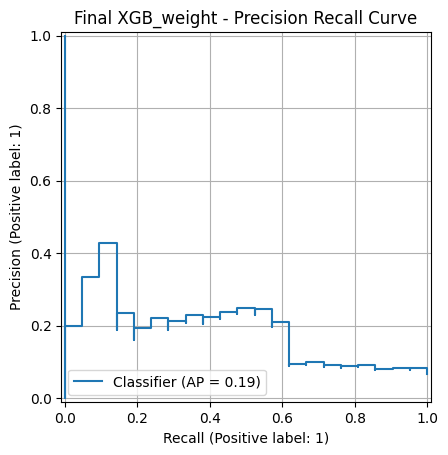

In [ ]:
#@title 4번 셀: 최종 모델 성능 평가 및 시각화
# ==========================================
# 4번 셀: 최종 모델 성능 평가 및 시각화
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    PrecisionRecallDisplay
)

# 1. Test 데이터의 불량 예측 점수
test_proba = best_model.predict_proba(X_test)[:, 1]

# 2. 선택한 Threshold로 최종 판정
y_pred_final = np.where(
    test_proba >= best_threshold,
    1, -1
)

# 3. 혼동행렬
print("최종 혼동행렬")
print(confusion_matrix(
    y_test, y_pred_final,
    labels=[-1, 1]
))

# 4. 전체 성능
print("\n최종 성능 평가")
print(classification_report(
    y_test, y_pred_final,
    labels=[-1, 1],
    digits=4,
    zero_division=0
))

# 5. Fail 클래스 주요 성능
print("Fail Recall:",
      round(recall_score(
          y_test, y_pred_final, pos_label=1
      ), 4))

print("Fail Precision:",
      round(precision_score(
          y_test, y_pred_final,
          pos_label=1, zero_division=0
      ), 4))

print("Fail F1:",
      round(f1_score(
          y_test, y_pred_final,
          pos_label=1, zero_division=0
      ), 4))

print("Average Precision:",
      round(average_precision_score(
          (y_test == 1).astype(int),
          test_proba
      ), 4))

# 6. 실제 선택된 변수 번호 확인
variance_mask = (
    best_model.named_steps['variance'].get_support()
)
remaining_cols = X_train.columns[variance_mask]

select_mask = (
    best_model.named_steps['selector'].get_support()
)
selected_cols = remaining_cols[select_mask]

print("\n최종 선택된 SECOM 변수 번호:")
print(selected_cols.tolist())

# 7. Precision-Recall 곡선
PrecisionRecallDisplay.from_predictions(
    (y_test == 1).astype(int),
    test_proba
)

# 선택한 모델 이름을 그래프 제목에 자동 반영
plt.title(
    f"Final {best_method} - Precision Recall Curve"
)

plt.grid(True)
plt.show()


In [ ]:
#@title 5번 셀: SHAP 분석
# ==========================================
# 5번 셀: SHAP 분석
# 최종 XGBoost 모델의 판단 근거 확인
# ==========================================

!pip install -q -U shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 현재 최종 모델 확인
clf = best_model.named_steps['classifier']

print("최종 AI:", type(clf).__name__)
print("최종 변수 수:", best_top_n)

assert type(clf).__name__ == 'XGBClassifier', \
    "현재 코드는 XGBoost 모델용입니다."

# 2. 선택된 변수의 원본 SECOM 번호 확인
variance_mask = best_model.named_steps[
    'variance'
].get_support()

remaining_cols = X_train.columns[variance_mask]

select_mask = best_model.named_steps[
    'selector'
].get_support()

selected_cols = remaining_cols[select_mask]

# 3. Test 데이터를 최종 모델 입력 형태로 변환
# 결측치 처리 -> 변수 선택 -> 표준화
X_shap_array = best_model[:-1].transform(X_test)

feature_names = [
    f"SECOM_{col}" for col in selected_cols
]

X_shap = pd.DataFrame(
    X_shap_array,
    columns=feature_names,
    index=X_test.index
)

print("SHAP 분석 데이터 크기:", X_shap.shape)

# 4. SHAP 계산
explainer = shap.TreeExplainer(clf)
shap_values = explainer(X_shap)

print("SHAP 계산 완료!")

# 5. 변수별 중요도 계산
# SHAP 절댓값의 평균이 클수록 판단에 큰 영향
importance = np.abs(shap_values.values).mean(axis=0)

shap_rank = pd.DataFrame({
    '변수': feature_names,
    'SHAP 중요도': importance
}).sort_values(
    'SHAP 중요도',
    ascending=False
)

print("\n===== SHAP 중요 변수 TOP 15 =====")
display(shap_rank.head(15).round(4))

# 6. 그래프 1: 중요 변수 순위
print("\n[그래프 1] SHAP 중요도 순위")
shap.plots.bar(
    shap_values,
    max_display=15
)

# 7. 그래프 2: 변수 값과 불량 판단 방향
print("\n[그래프 2] SHAP Summary Plot")
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

print("\nSHAP 분석 완료!")
print("기존 최종 모델과 예측 성능은 변경되지 않습니다.")
